In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd

# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
from pyCRLD.Utils import FlowPlot as fp

In [ ]:
env = SocialDilemma(R=3, S=-2, T=1, P=0)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=50., use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


[<Axes: >]

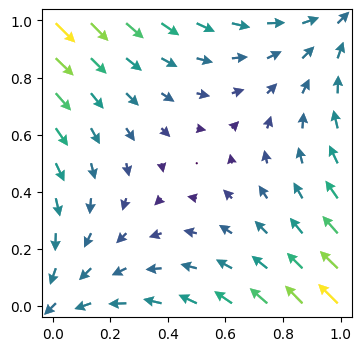

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0])  # agent 1 cooperates
y = ([1], [0], [0])  # agent 2 cooperates
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, axes=ax)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=50., use_prefactor=True)
db = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                learning_rates=0.1, discount_factors=0.9, 
                choice_intensities=50, Rmin=-2, Rmax=3,
                method='weights', wU=5, use_prefactor=True)

[<Axes: >]

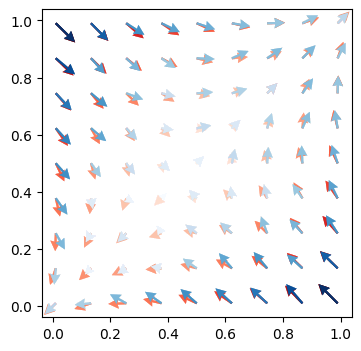

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
x = ([0], [0], [0]) 
y = ([1], [0], [0])
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
fp.plot_strategy_flow(db, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [ ]:
import matplotlib as mpl
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s

In [ ]:
def compare_levels(env,
                   level_list,  # level list
                   method,  # used method
                   x:tuple,  # which phase space axes to plot along x axes
                   res,  # specify range & resolution
                   NrRandom:int=4,  # how many random (in the other dimensions) stratgies for averaging 
                   traj_len:int=500,  # trajectory length
                   cmap='viridis',  # Colormap
                   acts=None,  # Action descriptions
                   conds=None,  # Conditions descriptions 
                   axes=None,  # Axes to plot into
                   verbose=False,  # shall I talk to you while working?
                   ):  
   

    # Fig and Axes
    states = 1
    fig, ax = plt.subplots(1, states, figsize=(states * 3.8, 2.8))
    cmap = mpl.cm.get_cmap(cmap)
    ext = np.linspace(0, 1, len(level_list))
    colors = cmap(tuple(ext))
    
    # x axis
    xs = res
    zero = np.zeros((len(xs)))

    # The Plots
    for j, l in enumerate(level_list):
        print(l)
        if method=='weights':
            mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                             learning_rates=0.1, discount_factors=0.9, 
                             choice_intensities=50., Rmin=-2, Rmax=3,
                             method=method, wU=l, use_prefactor=True)
        elif method=='expectile':
            mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                             learning_rates=0.1, discount_factors=0.9, 
                             choice_intensities=50., Rmin=-2, Rmax=3,
                             method=method, tau=l, use_prefactor=True)
        xinds = (x[0][0], x[1][0], x[2][0])  # fix this later
            
        # obtain the data to plot
        RPEs, dXs = _data_to_plot(mae, res, xinds, traj_len, NrRandom, 
                                  phasespace_items=_strategies, verbose=verbose)
        ax.plot(xs, dXs[0, :], color=colors[j], label=str(l))
        ax.plot(xs, zero, color="grey", ls='dashed')
        
    ax.set_ylabel("dX")
    ax.legend(bbox_to_anchor=(1.01, 1.01))
    
    return ax

In [ ]:
weights = np.array([.1, .4, .7, 1., 4., 7., 10.])
x = ([0], [0], [0]) 
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_16118/462850708.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


<Axes: ylabel='dX'>

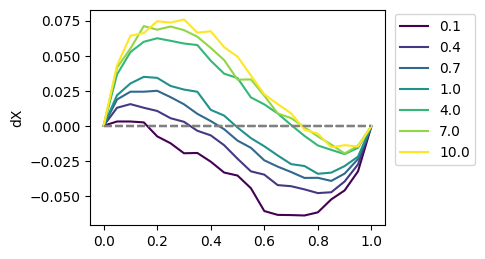

In [ ]:
compare_levels(env, weights, 'weights', x, res, NrRandom=100)

In [ ]:
expectiles = [0.10, 0.30, 0.50, 0.70, 0.90]

/tmp/ipykernel_16118/462850708.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.3
0.5
0.7
0.9


<Axes: ylabel='dX'>

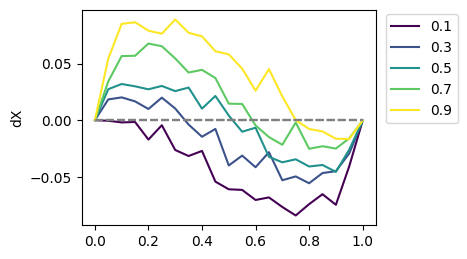

In [ ]:
compare_levels(env, expectiles, 'expectile', x, res, NrRandom=100)